Image shape: (28, 28)
HOG feature vector: (1296,)


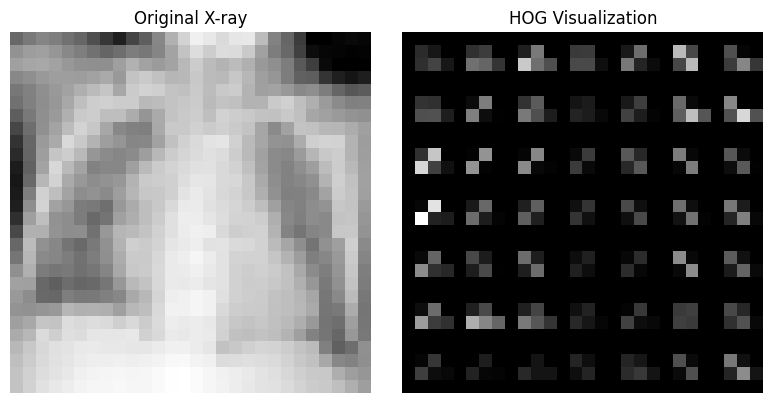

Image saved successfully!


In [2]:

import matplotlib.pyplot as plt
from medmnist import PneumoniaMNIST
from skimage.feature import hog

dataset = PneumoniaMNIST(
    split="train",
    download=True,
    size=28
)

image = dataset.imgs[0]

features, hog_image = hog(
    image,
    orientations=9,
    pixels_per_cell=(4, 4),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

print("Image shape:", image.shape)
print("HOG feature vector:", features.shape)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original X-ray")

axes[1].imshow(hog_image, cmap="gray")
axes[1].set_title("HOG Visualization")

for ax in axes:
    ax.axis("off")

from pathlib import Path

# Find the project folder
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Create the output folder if it doesn't exist
output_dir = project_root / "outputs" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

# Save the visualization
plt.tight_layout()
plt.savefig(output_dir / "hog_visualization.png", dpi=200)
plt.show()

print("Image saved successfully!")


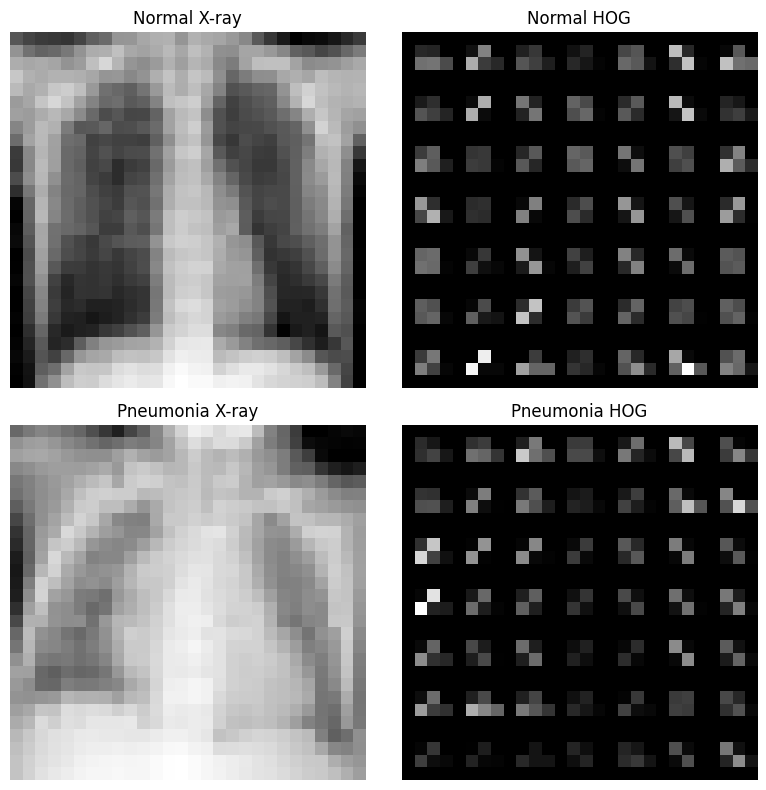

In [3]:
import numpy as np

labels = dataset.labels.ravel()

normal_idx = np.where(labels == 0)[0][0]
pneumonia_idx = np.where(labels == 1)[0][0]

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for row, idx in enumerate([normal_idx, pneumonia_idx]):
    img = dataset.imgs[idx]

    features, hog_img = hog(
        img,
        orientations=9,
        pixels_per_cell=(4, 4),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=True
    )

    label = "Normal" if row == 0 else "Pneumonia"

    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title(f"{label} X-ray")

    axes[row, 1].imshow(hog_img, cmap="gray")
    axes[row, 1].set_title(f"{label} HOG")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(output_dir / "hog_comparison.png", dpi=200)
plt.show()

In [4]:
import numpy as np

all_features = []

for img in dataset.imgs:
    feature_vector = hog(
        img,
        orientations=9,
        pixels_per_cell=(4, 4),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )
    all_features.append(feature_vector)

X_hog = np.array(all_features)

print("Total images:", len(dataset.imgs))
print("Feature matrix shape:", X_hog.shape)
print("Missing or invalid values:", np.isnan(X_hog).sum())

assert X_hog.shape == (len(dataset.imgs), 1296)
assert np.isfinite(X_hog).all()

print("All HOG features extracted successfully!")

Total images: 4708
Feature matrix shape: (4708, 1296)
Missing or invalid values: 0
All HOG features extracted successfully!


AttributeError: 'list' object has no attribute 'shape'

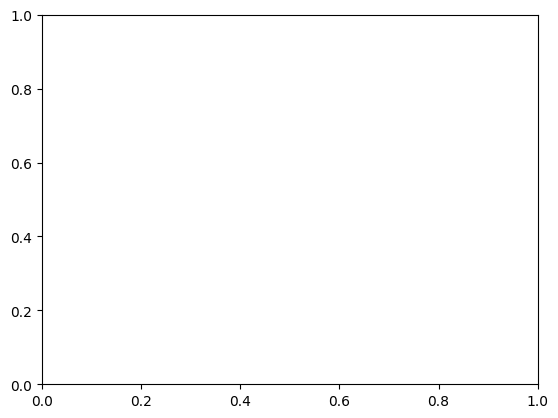

In [5]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

import numpy as np

cm = np.array([
    [116, 19],
    [20, 369]
])

# Find project folder
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = project_root / "outputs" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

# Create confusion matrix visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("HOG + SVM Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    output_dir / "svm_confusion_matrix.png",
    dpi=200
)

plt.show()

print("Confusion matrix saved successfully!")
